In [ ]:
import pandas as pd

df = pd.read_csv("../data/processed/real_balanced_reviews.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (120000, 3)
   rating                                             review sentiment
0     5.0  I have started every morning for the last 7 mo...  Positive
1     5.0  Thank goodness this pasta makes life for a glu...  Positive
2     5.0  I am the type of person who gets tired and sta...  Positive
3     5.0  The flavor of these is just amazing. They are ...  Positive
4     5.0  I have been using Coffee People Donut Shop for...  Positive


In [ ]:
aspects = {
    "taste": [
        "taste", "flavor", "flavour", "delicious",
        "tasty", "sweet", "bitter", "spicy"
    ],

    "quality": [
        "quality", "fresh", "stale", "ingredient",
        "ingredients", "organic"
    ],

    "price": [
        "price", "cost", "expensive", "cheap",
        "value", "worth"
    ],

    "packaging": [
        "package", "packaging", "box", "packed",
        "container", "seal"
    ],

    "delivery": [
        "delivery", "delivered", "shipping",
        "arrived", "shipment"
    ],

    "service": [
        "service", "seller", "customer support",
        "support", "refund"
    ]
}

print("Number of aspects:", len(aspects))
print("Aspects:", list(aspects.keys()))

Number of aspects: 6
Aspects: ['taste', 'quality', 'price', 'packaging', 'delivery', 'service']


In [ ]:
def extract_aspects(review):
    review_lower = review.lower()
    found_aspects = []

    for aspect, keywords in aspects.items():
        for keyword in keywords:
            if keyword in review_lower:
                found_aspects.append(aspect)
                break

    return found_aspects

In [ ]:
test_reviews = [
    "The taste is amazing and the packaging is excellent.",
    "The price is too expensive and delivery was very slow.",
    "The product quality is excellent."
]

for review in test_reviews:
    result = extract_aspects(review)

    print("Review:", review)
    print("Detected Aspects:", result)
    print("-" * 60)

Review: The taste is amazing and the packaging is excellent.
Detected Aspects: ['taste', 'packaging']
------------------------------------------------------------
Review: The price is too expensive and delivery was very slow.
Detected Aspects: ['price', 'delivery']
------------------------------------------------------------
Review: The product quality is excellent.
Detected Aspects: ['quality']
------------------------------------------------------------


In [ ]:
def analyze_review(review):
    detected_aspects = extract_aspects(review)

    review_tfidf = vectorizer.transform([review])
    sentiment = model.predict(review_tfidf)[0]

    return {
        "review": review,
        "sentiment": sentiment,
        "aspects": detected_aspects
    }

In [ ]:
import joblib

model = joblib.load("../data/processed/sentiment_model.pkl")
vectorizer = joblib.load("../data/processed/tfidf_vectorizer.pkl")

print("Model and vectorizer loaded successfully!")

Model and vectorizer loaded successfully!


In [ ]:
def analyze_review(review):
    detected_aspects = extract_aspects(review)

    review_tfidf = vectorizer.transform([review])
    sentiment = model.predict(review_tfidf)[0]

    return {
        "review": review,
        "sentiment": sentiment,
        "aspects": detected_aspects
    }

print("Analysis function ready!")

Analysis function ready!


In [ ]:
review = "The taste is amazing but the packaging is terrible."

result = analyze_review(review)

print("Review:", result["review"])
print("Overall Sentiment:", result["sentiment"])
print("Detected Aspects:", result["aspects"])

Review: The taste is amazing but the packaging is terrible.
Overall Sentiment: Negative
Detected Aspects: ['taste', 'packaging']


In [ ]:
def aspect_sentiment(review, aspect):
    review_lower = review.lower()

    # Find the position of the aspect in the review
    position = review_lower.find(aspect)

    if position == -1:
        return "Unknown"

    # Take a small section around the aspect
    start = max(0, position - 60)
    end = min(len(review), position + len(aspect) + 60)

    context = review[start:end]

    # Use the trained sentiment model on this local context
    context_tfidf = vectorizer.transform([context])
    sentiment = model.predict(context_tfidf)[0]

    return sentiment

In [ ]:
review = "The taste is amazing but the packaging is terrible."

detected_aspects = extract_aspects(review)

print("Review:", review)
print()

for aspect in detected_aspects:
    sentiment = aspect_sentiment(review, aspect)

    print("Aspect:", aspect)
    print("Sentiment:", sentiment)
    print("-" * 40)

Review: The taste is amazing but the packaging is terrible.

Aspect: taste
Sentiment: Negative
----------------------------------------
Aspect: packaging
Sentiment: Negative
----------------------------------------


In [ ]:
def complete_aspect_analysis(review):
    detected_aspects = extract_aspects(review)

    results = []

    for aspect in detected_aspects:
        sentiment = aspect_sentiment(review, aspect)

        results.append({
            "aspect": aspect,
            "sentiment": sentiment
        })

    return results

In [ ]:
review = "The taste is amazing but the packaging is terrible."

results = complete_aspect_analysis(review)

print("Review:", review)
print()

for result in results:
    print("Aspect:", result["aspect"])
    print("Sentiment:", result["sentiment"])
    print("-" * 40)

Review: The taste is amazing but the packaging is terrible.

Aspect: taste
Sentiment: Negative
----------------------------------------
Aspect: packaging
Sentiment: Negative
----------------------------------------


In [ ]:
positive_words = [
    "amazing", "excellent", "great", "good", "perfect",
    "delicious", "tasty", "love", "loved", "best",
    "fresh", "wonderful", "fantastic", "awesome"
]

negative_words = [
    "terrible", "bad", "poor", "awful", "worst",
    "hate", "hated", "disappointing", "stale", "expensive",
    "slow", "useless", "broken"
]

print("Sentiment word lists created successfully!")

Sentiment word lists created successfully!


In [ ]:
def improved_aspect_sentiment(review, aspect):
    review_lower = review.lower()

    # Find the aspect position
    position = review_lower.find(aspect)

    if position == -1:
        return "Unknown"

    # Look at nearby words
    start = max(0, position - 35)
    end = min(len(review_lower), position + len(aspect) + 35)

    context = review_lower[start:end]

    positive_count = sum(word in context for word in positive_words)
    negative_count = sum(word in context for word in negative_words)

    if positive_count > negative_count:
        return "Positive"
    elif negative_count > positive_count:
        return "Negative"
    else:
        return "Neutral"

In [ ]:
review = "The taste is amazing but the packaging is terrible."

detected_aspects = extract_aspects(review)

print("Review:", review)
print()

for aspect in detected_aspects:
    sentiment = improved_aspect_sentiment(review, aspect)

    print("Aspect:", aspect)
    print("Sentiment:", sentiment)
    print("-" * 40)

Review: The taste is amazing but the packaging is terrible.

Aspect: taste
Sentiment: Positive
----------------------------------------
Aspect: packaging
Sentiment: Neutral
----------------------------------------


In [ ]:
def improved_aspect_sentiment(review, aspect):
    review_lower = review.lower()

    # Split the review into smaller clauses
    clauses = re.split(r'\bbut\b|\band\b|\bhowever\b', review_lower)

    # Find the clause containing the aspect
    aspect_clause = ""

    for clause in clauses:
        if aspect.lower() in clause:
            aspect_clause = clause
            break

    if not aspect_clause:
        return "Unknown"

    positive_count = sum(
        word in aspect_clause
        for word in positive_words
    )

    negative_count = sum(
        word in aspect_clause
        for word in negative_words
    )

    if positive_count > negative_count:
        return "Positive"
    elif negative_count > positive_count:
        return "Negative"
    else:
        return "Neutral"

In [ ]:
import re

In [ ]:
review = "The taste is amazing but the packaging is terrible."

detected_aspects = extract_aspects(review)

print("Review:", review)
print()

for aspect in detected_aspects:
    sentiment = improved_aspect_sentiment(review, aspect)

    print("Aspect:", aspect)
    print("Sentiment:", sentiment)
    print("-" * 40)

Review: The taste is amazing but the packaging is terrible.

Aspect: taste
Sentiment: Positive
----------------------------------------
Aspect: packaging
Sentiment: Negative
----------------------------------------


In [ ]:
def complete_aspect_analysis(review):
    detected_aspects = extract_aspects(review)

    results = []

    for aspect in detected_aspects:
        sentiment = improved_aspect_sentiment(review, aspect)

        results.append({
            "aspect": aspect,
            "sentiment": sentiment
        })

    return results

print("Complete aspect analysis is ready!")

Complete aspect analysis is ready!


In [ ]:
test_reviews = [
    "The taste is amazing and the packaging is excellent.",
    "The taste is terrible but the packaging is beautiful.",
    "The price is expensive and the delivery is slow.",
    "The product quality is excellent but customer service is poor."
]

for review in test_reviews:
    print("Review:", review)

    results = complete_aspect_analysis(review)

    for result in results:
        print("  Aspect:", result["aspect"])
        print("  Sentiment:", result["sentiment"])

    print("=" * 60)

Review: The taste is amazing and the packaging is excellent.
  Aspect: taste
  Sentiment: Positive
  Aspect: packaging
  Sentiment: Positive
Review: The taste is terrible but the packaging is beautiful.
  Aspect: taste
  Sentiment: Negative
  Aspect: packaging
  Sentiment: Neutral
Review: The price is expensive and the delivery is slow.
  Aspect: price
  Sentiment: Negative
  Aspect: delivery
  Sentiment: Negative
Review: The product quality is excellent but customer service is poor.
  Aspect: quality
  Sentiment: Positive
  Aspect: service
  Sentiment: Negative


In [ ]:
analysis_results = []

for review in test_reviews:
    results = complete_aspect_analysis(review)

    for result in results:
        analysis_results.append({
            "review": review,
            "aspect": result["aspect"],
            "sentiment": result["sentiment"]
        })

aspect_df = pd.DataFrame(analysis_results)

print(aspect_df)

                                              review     aspect sentiment
0  The taste is amazing and the packaging is exce...      taste  Positive
1  The taste is amazing and the packaging is exce...  packaging  Positive
2  The taste is terrible but the packaging is bea...      taste  Negative
3  The taste is terrible but the packaging is bea...  packaging   Neutral
4   The price is expensive and the delivery is slow.      price  Negative
5   The price is expensive and the delivery is slow.   delivery  Negative
6  The product quality is excellent but customer ...    quality  Positive
7  The product quality is excellent but customer ...    service  Negative


In [ ]:
import pandas as pd

df_real = pd.read_csv("../data/processed/final_reviews.csv")

print("Dataset shape:", df_real.shape)

print("\nColumns:")
print(df_real.columns.tolist())

print("\nSentiment distribution:")
print(df_real["sentiment"].value_counts())

Dataset shape: (15, 4)

Columns:
['review', 'rating', 'clean_review', 'sentiment']

Sentiment distribution:
sentiment
Positive    6
Negative    6
Neutral     3
Name: count, dtype: int64


In [ ]:
import pandas as pd

df_balanced = pd.read_csv("../data/processed/real_balanced_reviews.csv")

print("Dataset shape:", df_balanced.shape)
print("\nColumns:")
print(df_balanced.columns.tolist())
print("\nSentiment distribution:")
print(df_balanced["sentiment"].value_counts())

Dataset shape: (120000, 3)

Columns:
['rating', 'review', 'sentiment']

Sentiment distribution:
sentiment
Positive    40000
Negative    40000
Neutral     40000
Name: count, dtype: int64


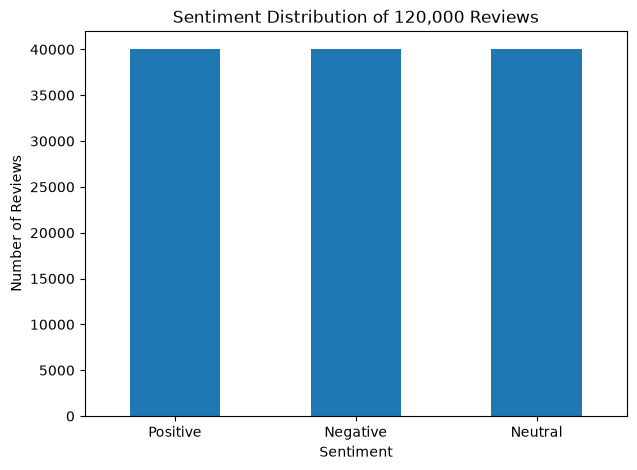

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = df_balanced["sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")

plt.title("Sentiment Distribution of 120,000 Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()

In [ ]:
rating_sentiment = pd.crosstab(
    df_balanced["rating"],
    df_balanced["sentiment"]
)

print(rating_sentiment)

sentiment  Negative  Neutral  Positive
rating                                
1.0           25492        0         0
2.0           14508        0         0
3.0               0    40000         0
4.0               0        0      7326
5.0               0        0     32674


In [ ]:
from collections import Counter

aspect_counts = Counter()

for review in df_balanced["review"]:
    detected_aspects = extract_aspects(review)

    for aspect in detected_aspects:
        aspect_counts[aspect] += 1

print("Aspect Mention Counts:")

for aspect, count in aspect_counts.most_common():
    print(f"{aspect}: {count}")

Aspect Mention Counts:
taste: 67881
price: 28412
packaging: 24935
quality: 24032
delivery: 10686
service: 4450


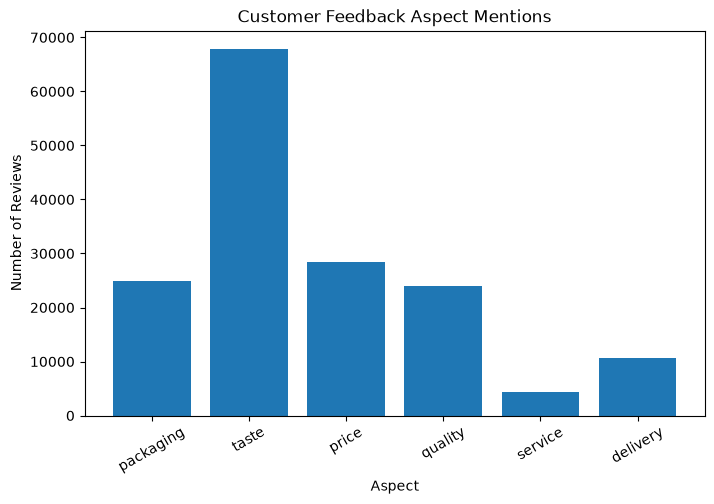

In [ ]:
import matplotlib.pyplot as plt

aspects_list = list(aspect_counts.keys())
counts_list = list(aspect_counts.values())

plt.figure(figsize=(8, 5))
plt.bar(aspects_list, counts_list)

plt.title("Customer Feedback Aspect Mentions")
plt.xlabel("Aspect")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=30)

plt.show()

In [ ]:
aspect_sentiment_counts = []

for review in df_balanced["review"]:
    detected_aspects = extract_aspects(review)

    for aspect in detected_aspects:
        sentiment = improved_aspect_sentiment(review, aspect)

        aspect_sentiment_counts.append({
            "aspect": aspect,
            "sentiment": sentiment
        })

aspect_sentiment_df = pd.DataFrame(aspect_sentiment_counts)

print("Aspect-Sentiment Analysis:")
print(aspect_sentiment_df.head(20))

Aspect-Sentiment Analysis:
       aspect sentiment
0   packaging   Unknown
1       taste   Unknown
2       taste   Unknown
3       price   Neutral
4   packaging   Unknown
5       taste   Neutral
6     quality   Neutral
7       price   Unknown
8   packaging   Unknown
9       taste  Negative
10      taste   Neutral
11    quality   Unknown
12      price   Unknown
13      taste   Unknown
14    quality   Unknown
15    service  Positive
16      taste  Positive
17      taste  Positive
18    quality   Unknown
19      taste   Unknown


In [ ]:
aspect_summary = pd.crosstab(
    aspect_sentiment_df["aspect"],
    aspect_sentiment_df["sentiment"]
)

print("Aspect-Sentiment Summary:")
print(aspect_summary)

Aspect-Sentiment Summary:
sentiment  Negative  Neutral  Positive  Unknown
aspect                                         
delivery         87      804       482     9313
packaging       366     2576      1111    20882
price           886     8494      5654    13378
quality         589     3613      2365    17465
service         116      823       685     2826
taste          3786    23289     15131    25675


In [ ]:
aspect_percentage = aspect_summary.div(
    aspect_summary.sum(axis=1),
    axis=0
) * 100

aspect_percentage = aspect_percentage.round(2)

print("Aspect Sentiment Percentages:")
print(aspect_percentage)

Aspect Sentiment Percentages:
sentiment  Negative  Neutral  Positive  Unknown
aspect                                         
delivery       0.81     7.52      4.51    87.15
packaging      1.47    10.33      4.46    83.75
price          3.12    29.90     19.90    47.09
quality        2.45    15.03      9.84    72.67
service        2.61    18.49     15.39    63.51
taste          5.58    34.31     22.29    37.82


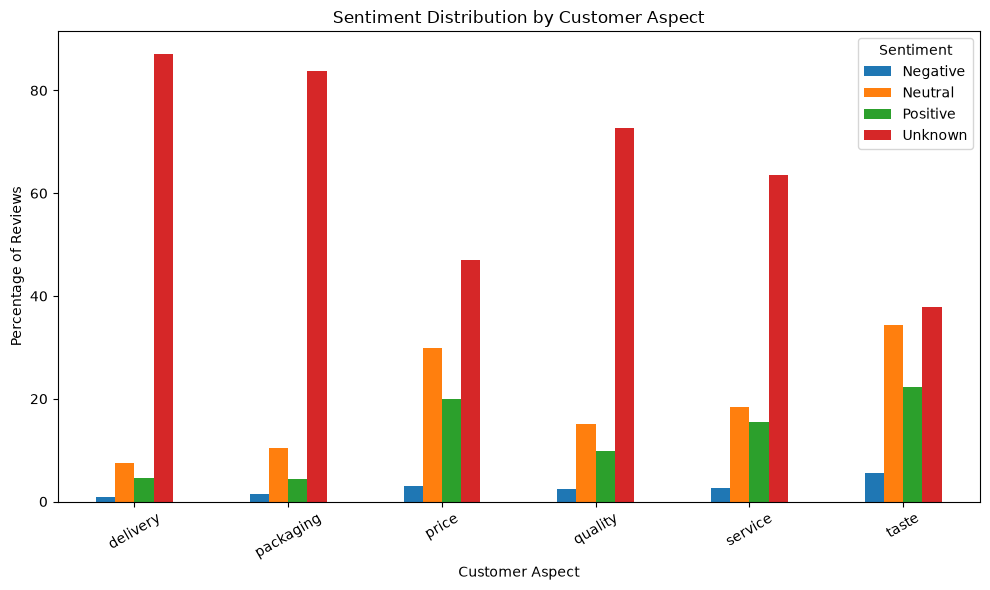

In [ ]:
aspect_percentage.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Customer Aspect")
plt.xlabel("Customer Aspect")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=30)
plt.legend(title="Sentiment")
plt.tight_layout()

plt.show()

In [ ]:
negative_aspects = (
    aspect_percentage["Negative"]
    .sort_values(ascending=False)
)

print("Negative Feedback by Aspect:")
print(negative_aspects)

Negative Feedback by Aspect:
aspect
taste        5.58
price        3.12
service      2.61
quality      2.45
packaging    1.47
delivery     0.81
Name: Negative, dtype: float64


In [ ]:
priority_df = pd.DataFrame({
    "aspect": negative_aspects.index,
    "negative_percentage": negative_aspects.values
})

def assign_priority(value):
    if value >= 40:
        return "High"
    elif value >= 20:
        return "Medium"
    else:
        return "Low"

priority_df["priority"] = priority_df["negative_percentage"].apply(
    assign_priority
)

print("Aspect Priority Analysis:")
print(priority_df)

Aspect Priority Analysis:
      aspect  negative_percentage priority
0      taste                 5.58      Low
1      price                 3.12      Low
2    service                 2.61      Low
3    quality                 2.45      Low
4  packaging                 1.47      Low
5   delivery                 0.81      Low


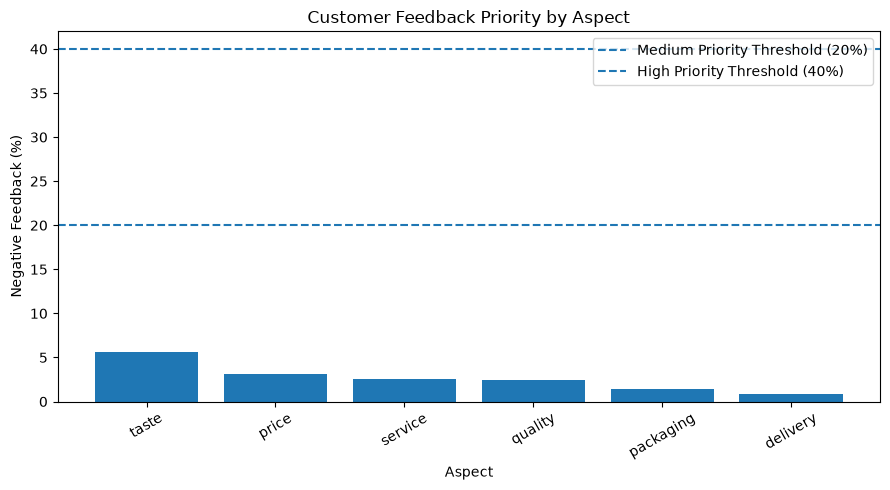

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    priority_df["aspect"],
    priority_df["negative_percentage"]
)

plt.axhline(
    y=20,
    linestyle="--",
    label="Medium Priority Threshold (20%)"
)

plt.axhline(
    y=40,
    linestyle="--",
    label="High Priority Threshold (40%)"
)

plt.title("Customer Feedback Priority by Aspect")
plt.xlabel("Aspect")
plt.ylabel("Negative Feedback (%)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()

plt.show()

In [ ]:
print("===== CUSTOMER FEEDBACK INSIGHTS =====\n")

for _, row in priority_df.iterrows():

    aspect = row["aspect"]
    negative = row["negative_percentage"]

    positive = aspect_percentage.loc[aspect, "Positive"]

    if negative >= 40:
        insight = "High negative feedback. This aspect needs immediate attention."
    elif negative >= 20:
        insight = "Moderate negative feedback. This aspect should be monitored."
    else:
        insight = "Low negative feedback. Customers are generally satisfied with this aspect."

    print(f"{aspect.upper()}")
    print(f"Negative Feedback: {negative:.2f}%")
    print(f"Positive Feedback: {positive:.2f}%")
    print(f"Insight: {insight}")
    print("-" * 60)

===== CUSTOMER FEEDBACK INSIGHTS =====

TASTE
Negative Feedback: 5.58%
Positive Feedback: 22.29%
Insight: Low negative feedback. Customers are generally satisfied with this aspect.
------------------------------------------------------------
PRICE
Negative Feedback: 3.12%
Positive Feedback: 19.90%
Insight: Low negative feedback. Customers are generally satisfied with this aspect.
------------------------------------------------------------
SERVICE
Negative Feedback: 2.61%
Positive Feedback: 15.39%
Insight: Low negative feedback. Customers are generally satisfied with this aspect.
------------------------------------------------------------
QUALITY
Negative Feedback: 2.45%
Positive Feedback: 9.84%
Insight: Low negative feedback. Customers are generally satisfied with this aspect.
------------------------------------------------------------
PACKAGING
Negative Feedback: 1.47%
Positive Feedback: 4.46%
Insight: Low negative feedback. Customers are generally satisfied with this aspect.
-----

In [ ]:
aspect_sentiment_df.to_csv(
    "../data/processed/aspect_sentiment_results.csv",
    index=False
)

priority_df.to_csv(
    "../data/processed/aspect_priority_results.csv",
    index=False
)

print("Aspect sentiment results saved successfully!")
print("Priority analysis results saved successfully!")

Aspect sentiment results saved successfully!
Priority analysis results saved successfully!


In [ ]:
import torch
import transformers

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Emotion detection libraries are ready!")

PyTorch version: 2.14.0+cpu
Transformers version: 5.17.0
Emotion detection libraries are ready!


In [ ]:
from transformers import pipeline

emotion_classifier = pipeline(
    "text-classification",
    model="j-hartmann/emotion-english-distilroberta-base"
)

print("Emotion detection model loaded successfully!")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Emotion detection model loaded successfully!


In [ ]:
test_emotions = [
    "I absolutely love this product, it is amazing!",
    "I am extremely angry and disappointed with this product.",
    "The product is okay, nothing special.",
    "I am very happy with the quality and taste.",
    "This product is terrible and I hate it."
]

for review in test_emotions:
    result = emotion_classifier(review)[0]

    print("Review:", review)
    print("Emotion:", result["label"])
    print("Confidence:", round(result["score"], 3))
    print("-" * 60)

Review: I absolutely love this product, it is amazing!
Emotion: joy
Confidence: 0.782
------------------------------------------------------------
Review: I am extremely angry and disappointed with this product.
Emotion: anger
Confidence: 0.988
------------------------------------------------------------
Review: The product is okay, nothing special.
Emotion: neutral
Confidence: 0.859
------------------------------------------------------------
Review: I am very happy with the quality and taste.
Emotion: joy
Confidence: 0.99
------------------------------------------------------------
Review: This product is terrible and I hate it.
Emotion: disgust
Confidence: 0.807
------------------------------------------------------------


In [ ]:
emotion_reviews = df_balanced["review"].sample(
    n=1000,
    random_state=42
).tolist()

emotion_results = []

for review in emotion_reviews:
    result = emotion_classifier(
        review,
        truncation=True,
        max_length=512
    )[0]

    emotion_results.append({
        "review": review,
        "emotion": result["label"],
        "confidence": result["score"]
    })

emotion_df = pd.DataFrame(emotion_results)

print("Emotion analysis completed!")
print("Number of reviews analyzed:", len(emotion_df))

print("\nEmotion distribution:")
print(emotion_df["emotion"].value_counts())

Emotion analysis completed!
Number of reviews analyzed: 1000

Emotion distribution:
emotion
neutral     406
joy         211
disgust     162
sadness      96
surprise     88
fear         20
anger        17
Name: count, dtype: int64


In [ ]:
emotion_df.to_csv(
    "../data/processed/emotion_results.csv",
    index=False
)

print("Emotion analysis results saved successfully!")
print("File: emotion_results.csv")

Emotion analysis results saved successfully!
File: emotion_results.csv


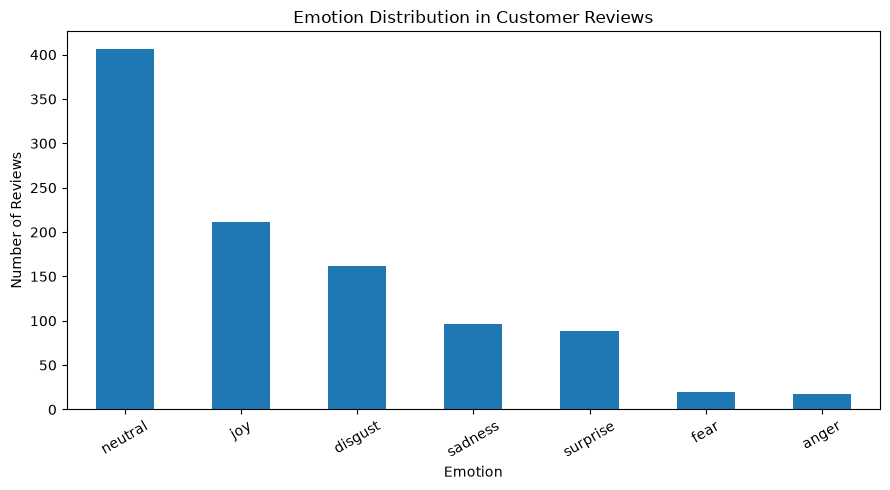

In [ ]:
emotion_counts = emotion_df["emotion"].value_counts()

plt.figure(figsize=(9, 5))

emotion_counts.plot(kind="bar")

plt.title("Emotion Distribution in Customer Reviews")
plt.xlabel("Emotion")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# Combine sentiment and emotion results

emotion_analysis = emotion_df.merge(
    df_balanced[["review", "sentiment"]],
    on="review",
    how="left"
)

print("Combined emotion + sentiment analysis:")
print(emotion_analysis.head())

print("\nSentiment distribution:")
print(emotion_analysis["sentiment"].value_counts())

print("\nEmotion distribution:")
print(emotion_analysis["emotion"].value_counts())

Combined emotion + sentiment analysis:
                                              review   emotion  confidence  \
0  Don''t buy it. My dog loves the treat. HOWEVER...   disgust    0.364479   
1  Don''t buy it. My dog loves the treat. HOWEVER...   disgust    0.364479   
2  I was very disappointed with this purchase! Th...  surprise    0.333092   
3  I was very disappointed with this purchase! Th...  surprise    0.333092   
4  I was very disappointed with this purchase! Th...  surprise    0.333092   

  sentiment  
0  Negative  
1  Negative  
2  Negative  
3  Negative  
4  Negative  

Sentiment distribution:
sentiment
Negative    896
Neutral     828
Positive    417
Name: count, dtype: int64

Emotion distribution:
emotion
neutral     906
disgust     408
joy         328
sadness     234
surprise    206
fear         40
anger        19
Name: count, dtype: int64


In [ ]:
sentiment_emotion_table = pd.crosstab(
    emotion_analysis["sentiment"],
    emotion_analysis["emotion"]
)

print("Sentiment vs Emotion:")
print(sentiment_emotion_table)

Sentiment vs Emotion:
emotion    anger  disgust  fear  joy  neutral  sadness  surprise
sentiment                                                       
Negative      11      249    20   32      348      151        85
Neutral        3      142    15  109      394       72        93
Positive       5       17     5  187      164       11        28


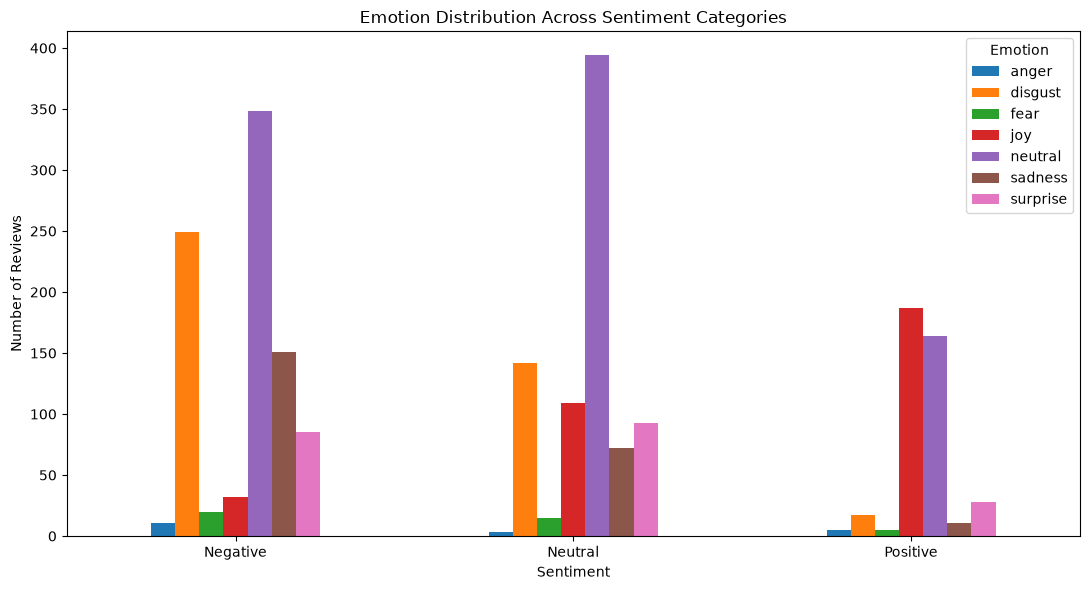

In [ ]:
sentiment_emotion_table.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Emotion Distribution Across Sentiment Categories")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Emotion")
plt.tight_layout()

plt.show()

In [ ]:
dominant_emotions = (
    emotion_analysis
    .groupby("sentiment")["emotion"]
    .agg(lambda x: x.value_counts().index[0])
)

print("Dominant Emotion for Each Sentiment:")
print(dominant_emotions)

Dominant Emotion for Each Sentiment:
sentiment
Negative    neutral
Neutral     neutral
Positive        joy
Name: emotion, dtype: str


In [ ]:
aspect_emotion_results = []

for _, row in emotion_analysis.iterrows():
    review = row["review"]
    emotion = row["emotion"]

    detected_aspects = extract_aspects(review)

    for aspect in detected_aspects:
        aspect_emotion_results.append({
            "aspect": aspect,
            "emotion": emotion
        })

aspect_emotion_df = pd.DataFrame(aspect_emotion_results)

print("Aspect-Emotion Analysis:")
print(aspect_emotion_df.head(20))

Aspect-Emotion Analysis:
       aspect   emotion
0   packaging  surprise
1   packaging  surprise
2   packaging  surprise
3   packaging  surprise
4       taste       joy
5     quality   neutral
6       price   neutral
7       price  surprise
8    delivery  surprise
9       taste   neutral
10      price   neutral
11  packaging   neutral
12    service   neutral
13      taste       joy
14  packaging       joy
15      taste   neutral
16  packaging   neutral
17      taste   neutral
18  packaging   neutral
19      taste   neutral


In [ ]:
aspect_emotion_summary = pd.crosstab(
    aspect_emotion_df["aspect"],
    aspect_emotion_df["emotion"]
)

print("Aspect vs Emotion Summary:")
print(aspect_emotion_summary)

Aspect vs Emotion Summary:
emotion    anger  disgust  fear  joy  neutral  sadness  surprise
aspect                                                          
delivery       1        5     6   12       53       24        49
packaging      5      102     2   50      173       92        29
price          3       81    12   67      281       60        50
quality        7      121     9   38      252       44        44
service        0        9     0    5       14       16         6
taste          6      270    17  202      571       79       112


In [ ]:
# Find the dominant emotion for each customer aspect

dominant_aspect_emotions = (
    aspect_emotion_df
    .groupby("aspect")["emotion"]
    .agg(lambda x: x.value_counts().index[0])
)

print("Dominant Emotion for Each Aspect:")
print(dominant_aspect_emotions)

Dominant Emotion for Each Aspect:
aspect
delivery     neutral
packaging    neutral
price        neutral
quality      neutral
service      sadness
taste        neutral
Name: emotion, dtype: str


In [ ]:
# Create a combined customer intelligence summary

customer_intelligence = priority_df.copy()

customer_intelligence["positive_percentage"] = [
    aspect_percentage.loc[aspect, "Positive"]
    for aspect in customer_intelligence["aspect"]
]

customer_intelligence["neutral_percentage"] = [
    aspect_percentage.loc[aspect, "Neutral"]
    for aspect in customer_intelligence["aspect"]
]

customer_intelligence["dominant_emotion"] = [
    dominant_aspect_emotions.get(aspect, "Unknown")
    for aspect in customer_intelligence["aspect"]
]

customer_intelligence = customer_intelligence[
    [
        "aspect",
        "negative_percentage",
        "positive_percentage",
        "neutral_percentage",
        "dominant_emotion",
        "priority"
    ]
]

print("===== CUSTOMER INTELLIGENCE SUMMARY =====")
print(customer_intelligence)

## Actionable Customer Intelligence

Convert the aspect analysis into ranked recommendations and validate the relationship between star ratings and predicted sentiment.

In [ ]:
required_columns = {
    "priority_df": {"aspect", "negative_percentage", "priority"},
    "aspect_percentage": {"Positive", "Neutral", "Negative"},
    "dominant_aspect_emotions": set()
}

missing_priority_columns = required_columns["priority_df"] - set(priority_df.columns)
missing_sentiment_columns = required_columns["aspect_percentage"] - set(aspect_percentage.columns)

if missing_priority_columns or missing_sentiment_columns:
    raise ValueError(
        f"Missing columns: priority_df={missing_priority_columns}, "
        f"aspect_percentage={missing_sentiment_columns}"
    )

customer_intelligence["recommended_action"] = customer_intelligence.apply(
    lambda row: (
        "Investigate and improve immediately"
        if row["priority"] == "High"
        else "Monitor and test targeted improvements"
        if row["priority"] == "Medium"
        else "Maintain performance and monitor trends"
    ),
    axis=1
)

customer_intelligence = customer_intelligence.sort_values(
    ["priority", "negative_percentage"],
    ascending=[True, False],
    key=lambda values: values.map({"High": 0, "Medium": 1, "Low": 2})
    if values.name == "priority"
    else values
).reset_index(drop=True)

customer_intelligence.to_csv(
    "../data/processed/customer_intelligence_summary.csv",
    index=False
)

print("Actionable customer intelligence:")
print(customer_intelligence.to_string(index=False))

## Rating and Sentiment Consistency Check

Use star ratings as an independent signal to find reviews that deserve manual inspection.

In [ ]:
rating_sentiment_summary = pd.crosstab(
    df_balanced["rating"],
    df_balanced["sentiment"],
    normalize="index"
).mul(100).round(2)

print("Sentiment percentage within each rating:")
print(rating_sentiment_summary)

rating_sentiment_summary.to_csv(
    "../data/processed/rating_sentiment_summary.csv"
)

In [ ]:
rating_mismatch_reviews = df_balanced[
    (
        (df_balanced["rating"] >= 4)
        & (df_balanced["sentiment"] == "Negative")
    )
    | (
        (df_balanced["rating"] <= 2)
        & (df_balanced["sentiment"] == "Positive")
    )
].copy()

rating_mismatch_reviews.to_csv(
    "../data/processed/rating_sentiment_mismatches.csv",
    index=False
)

print("Potential rating/sentiment mismatches:", len(rating_mismatch_reviews))
print(rating_mismatch_reviews.head(10).to_string(index=False))

In [ ]:
executive_kpis = pd.DataFrame({
    "metric": [
        "reviews_analyzed",
        "average_rating",
        "positive_review_percentage",
        "negative_review_percentage",
        "rating_sentiment_mismatch_count"
    ],
    "value": [
        len(df_balanced),
        round(df_balanced["rating"].mean(), 2),
        round((df_balanced["sentiment"] == "Positive").mean() * 100, 2),
        round((df_balanced["sentiment"] == "Negative").mean() * 100, 2),
        len(rating_mismatch_reviews)
    ]
})

executive_kpis.to_csv(
    "../data/processed/executive_kpis.csv",
    index=False
)

print("===== EXECUTIVE KPIs =====")
print(executive_kpis.to_string(index=False))